In [1]:
import os
#os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import gc

from matplotlib import pyplot
pyplot.rcParams['figure.figsize'] = [10, 5]

import numpy as np
import cv2
import sys
from io import StringIO

import torch
from torch import nn
import torch.utils.data as data
import torch.optim as optim
import torch.nn.functional as F

from focal_loss import FocalLoss

from fuzzy_control import act_alpha

print(torch.__version__)


1.8.1+cu102


In [2]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        
        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu(x)
        
        return x

class Encoder(nn.Module):
    def __init__(self, in_channels, out_channels, pool=True):
        super().__init__()
        self.pool = pool
        self.conv_block = ConvBlock(in_channels, out_channels)
        if self.pool:
            self.max_pool = nn.MaxPool2d((2,2))#kernel_size=2, stride=2)

    def forward(self, x):
        x = self.conv_block(x)
        before_pool = x
        if self.pool:
            x = self.max_pool(x)
        return before_pool,x#x, before_pool

class Decoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        # self.upsample = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2, padding=0)
        self.conv_block = ConvBlock(in_channels, out_channels)

    def forward(self, x, down_tensor):
        x = self.up(x)
        #print("x shape:", x.shape)
        #print("down_tensor shape:", down_tensor.shape)
        x = torch.cat([x, down_tensor], axis=1)
        #print("x concatenado:", x.shape)
        x = self.conv_block(x)
        #print("--------------------")
        return x

In [3]:
class UNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.encoder1 = Encoder(3, 64, pool=True)  # No hacemos pooling para el primer bloque de codificador
        self.encoder2 = Encoder(64, 128)
        self.encoder3 = Encoder(128, 256)
        self.encoder4 = Encoder(256, 512)

        self.center = ConvBlock(512, 1024)

        self.decoder4 = Decoder(1024,512)#1024+512, 512)
        self.decoder3 = Decoder(512,256)#512+256, 256)
        self.decoder2 = Decoder(256,128)#256+128, 128)
        self.decoder1 = Decoder(128,64)#128+64, 64)

        self.output_conv = nn.Conv2d(64, num_classes, kernel_size=1, padding=0)

    def forward(self, x):
        s1, p1 = self.encoder1(x)
        s2, p2 = self.encoder2(p1)
        s3, p3 = self.encoder3(p2)
        s4, p4 = self.encoder4(p3)

        b = self.center(p4)

        d1 = self.decoder4(b, s4)
        d2 = self.decoder3(d1, s3)
        d3 = self.decoder2(d2, s2)
        d4 = self.decoder1(d3, s1)

        out = self.output_conv(d4)
        return out

In [4]:
#no se usa
def one_hot_to_original(masks_one_hot):
    return np.argmax(masks_one_hot, axis=-1) + 1

#funcion para cargar las imagenes npy
def load_images_npy(folder_path, folder_objetive):
    image_files = [file for file in os.listdir(folder_path) if file.endswith('.npy')]

    images = []
    for file in image_files:
        file_path = os.path.join(folder_path, file)
        img = np.load(file_path)
        images.append(img)

    array_images = np.array(images)
    np.save(folder_objetive, array_images)
    return array_images

#ver las dimensiones de los arrays.
def check_array_sizes_and_types(X_train, X_val, y_train, y_val, x_test, y_test):
    print("Dimensiones de X_train:", X_train.shape, " Tipo de datos:", X_train.dtype)
    print("Dimensiones de X_val:", X_val.shape, " Tipo de datos:", X_val.dtype)
    print("Dimensiones de y_train:", y_train.shape, " Tipo de datos:", y_train.dtype)
    print("Dimensiones de y_val:", y_val.shape, " Tipo de datos:", y_val.dtype)
    print("Dimensiones de x_test:", x_test.shape, " Tipo de datos:", x_test.dtype)
    print("Dimensiones de y_test:", y_test.shape, " Tipo de datos:", y_test.dtype)




In [5]:
num_classes = 5  # Para segmentar 4 órganos
#epochs = 2400
batch_size = 4
smooth = 10e-6

In [6]:
#Path de las imagenes para cada particion
path_to_train_images = "/home/graciela/Adrian/Segmentacion_Unet_pytorch/MR_DATA_31_Marzo/chaos_train/orig/"
path_to_val_images = "/home/graciela/Adrian/Segmentacion_Unet_pytorch/MR_DATA_31_Marzo/chaos_val/orig/"
path_to_test_images = "/home/graciela/Adrian/Segmentacion_Unet_pytorch/MR_DATA_31_Marzo/chaos_test/orig/"


#lo mismo pero para las mascaras
path_to_train_mask = "/home/graciela/Adrian/Segmentacion_Unet_pytorch/MR_DATA_31_Marzo/chaos_train/mask/"
path_to_val_mask = "/home/graciela/Adrian/Segmentacion_Unet_pytorch/MR_DATA_31_Marzo/chaos_val/mask/"
path_to_test_mask = "/home/graciela/Adrian/Segmentacion_Unet_pytorch/MR_DATA_31_Marzo/chaos_test/mask/"



#Path donde se guardaran las imagenes para cada particion
path_to_save_train_images = "/home/graciela/Adrian/Segmentacion_Unet_pytorch/MR_Data_1archivo/chaos_train/orig/X_train.npy"
path_to_save_val_images = "/home/graciela/Adrian/Segmentacion_Unet_pytorch/MR_Data_1archivo/chaos_val/orig/X_val.npy"
path_to_save_test_images = "/home/graciela/Adrian/Segmentacion_Unet_pytorch/MR_Data_1archivo/chaos_test/orig/X_test.npy"


#lo mismo pero para las mascaras
path_to_save_train_mask = "/home/graciela/Adrian/Segmentacion_Unet_pytorch/MR_Data_1archivo/chaos_train/mask/Y_train.npy"
path_to_save_val_mask = "/home/graciela/Adrian/Segmentacion_Unet_pytorch/MR_Data_1archivo/chaos_val/mask/Y_val.npy"
path_to_save_test_mask = "/home/graciela/Adrian/Segmentacion_Unet_pytorch/MR_Data_1archivo/chaos_test/mask/Y_test.npy"


X_train = load_images_npy(path_to_train_images,path_to_save_train_images)
X_val = load_images_npy(path_to_val_images,path_to_save_val_images)
X_test = load_images_npy(path_to_test_images,path_to_save_test_images)

Y_train = load_images_npy(path_to_train_mask,path_to_save_train_mask)
Y_val = load_images_npy(path_to_val_mask,path_to_save_val_mask)
Y_test = load_images_npy(path_to_test_mask,path_to_save_test_mask)

# Verificar tamaños y tipos de datos
check_array_sizes_and_types(X_train, X_val, Y_train, Y_val, X_test, Y_test)

Dimensiones de X_train: (470, 256, 256, 3)  Tipo de datos: float64
Dimensiones de X_val: (65, 256, 256, 3)  Tipo de datos: float64
Dimensiones de y_train: (470, 256, 256)  Tipo de datos: int64
Dimensiones de y_val: (65, 256, 256)  Tipo de datos: int64
Dimensiones de x_test: (112, 256, 256, 3)  Tipo de datos: float64
Dimensiones de y_test: (112, 256, 256)  Tipo de datos: int64


In [7]:
Y_train_torch = torch.from_numpy(Y_train)
Y_val_torch = torch.from_numpy(Y_val)
Y_test_torch = torch.from_numpy(Y_test)

y_train_one_hot = F.one_hot(Y_train_torch, num_classes=num_classes).permute(0, 3, 1, 2).to(torch.float32)
y_val_one_hot = F.one_hot(Y_val_torch, num_classes=num_classes).permute(0, 3, 1, 2).to(torch.float32)
y_test_one_hot = F.one_hot(Y_test_torch, num_classes=num_classes).permute(0, 3, 1, 2).to(torch.float32)

print("Dimensiones de y_train_one_hot:", y_train_one_hot.shape, " Tipo de datos:", y_train_one_hot.dtype)
print("Dimensiones de y_val_one_hot:", y_val_one_hot.shape, " Tipo de datos:", y_val_one_hot.dtype)
print("Dimensiones de y_test_one_hot:", y_test_one_hot.shape, " Tipo de datos:", y_test_one_hot.dtype)

Dimensiones de y_train_one_hot: torch.Size([470, 5, 256, 256])  Tipo de datos: torch.float32
Dimensiones de y_val_one_hot: torch.Size([65, 5, 256, 256])  Tipo de datos: torch.float32
Dimensiones de y_test_one_hot: torch.Size([112, 5, 256, 256])  Tipo de datos: torch.float32


In [8]:
class_sizes = [0,0,0,0,0]
for y in y_train_one_hot.numpy():
    for i in range(256):
        for j in range(256):
            class_sizes += y[:,i,j]
class_sizes



array([29366867.,  1036895.,   116518.,   115360.,   166280.])

In [9]:
class_sizes /= class_sizes.sum()
class_sizes

array([0.95341027, 0.03366332, 0.00378282, 0.00374522, 0.00539836])

In [10]:
X_train = torch.from_numpy(X_train).permute(0, 3, 1, 2)  # Asegúrate de que los canales estén en la dimensión correcta
dataset_train = data.TensorDataset(X_train, y_train_one_hot)
dataloader_train = data.DataLoader(dataset_train, batch_size=batch_size, shuffle=True)

X_val = torch.from_numpy(X_val).permute(0, 3, 1, 2)  # Asegúrate de que los canales estén en la dimensión correcta
dataset_val = data.TensorDataset(X_val, y_val_one_hot)
dataloader_val = data.DataLoader(dataset_val, batch_size=batch_size, shuffle=True)

X_test = torch.from_numpy(X_test).permute(0, 3, 1, 2)  # Asegúrate de que los canales estén en la dimensión correcta
dataset_test = data.TensorDataset(X_test, y_test_one_hot)
dataloader_test = data.DataLoader(dataset_test, batch_size=batch_size, shuffle=False)




In [11]:
# Obtén el primer lote de datos del DataLoader
dataiter_train = iter(dataloader_train)
images_train, labels_train = next(dataiter_train)
# Obtén el primer lote de datos del DataLoader
dataiter_val = iter(dataloader_val)
images_val, labels_val = next(dataiter_val)
# Obtén el primer lote de datos del DataLoader
dataiter_test = iter(dataloader_test)
x_temp = next(dataiter_test)
images_test, labels_test = next(dataiter_test)
# Imprime las formas de las imágenes y las etiquetas
print('Images shape:', images_train.shape, 'Labels shape:', labels_train.shape)
# Imprime las formas de las imágenes y las etiquetas
print('Images shape:', images_val.shape, 'Labels shape:', labels_val.shape)
# Imprime las formas de las imágenes y las etiquetas
print('Images shape:', images_test.shape, 'Labels shape:', labels_test.shape)



Images shape: torch.Size([4, 3, 256, 256]) Labels shape: torch.Size([4, 5, 256, 256])
Images shape: torch.Size([4, 3, 256, 256]) Labels shape: torch.Size([4, 5, 256, 256])
Images shape: torch.Size([4, 3, 256, 256]) Labels shape: torch.Size([4, 5, 256, 256])


In [12]:

model = UNet(num_classes)

In [13]:
# Selecciona el dispositivo para entrenamiento, si tienes una GPU disponible, usarla para acelerar el entrenamiento.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Mueve el modelo al dispositivo seleccionado
model = model.to(device)

# Define la función de pérdida y el optimizador
criterion = FocalLoss(gamma=2, alpha=[0.5,0.5,0.5,0.5,0.5])
optimizer = optim.Adam(model.parameters(),lr=1e-7)

# Bucle de entrenamiento
num_epochs = 120  # El número de épocas es un hiperparámetro que puedes ajustar
print(device)

cuda


In [14]:
import pandas as pd
from ignite.metrics import ConfusionMatrix, IoU, DiceCoefficient
from IPython import display

cm_IoU = ConfusionMatrix(num_classes=5)
cm_Dice = ConfusionMatrix(num_classes=5)
iou_metric = IoU(cm_IoU)
iou_no_bg_metric = iou_metric[1:]  # We assume that the background index is 9
mean_iou_no_bg_metric = iou_no_bg_metric.mean()
dice_metric = DiceCoefficient(cm_Dice)




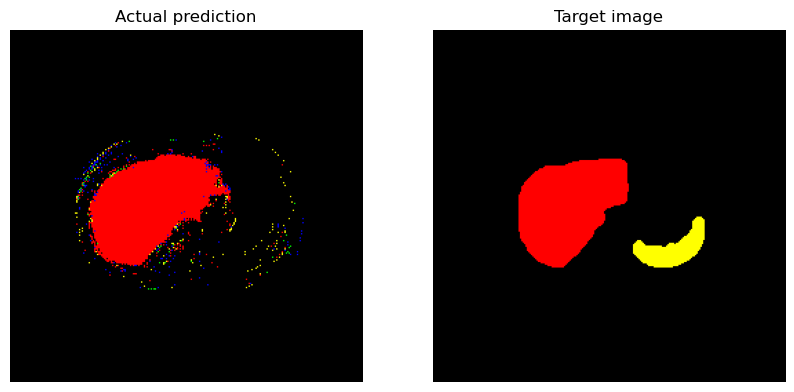

,Dice,IoU,alpha,loss,mIoU,val_Dice,val_IoU,val_loss,val_mIoU
epoch,,,,,,,,,
115,"[0.98458, 0.85024, 0.00336, 0.00528, 0.05391]","[0.7395, 0.00168, 0.00265, 0.0277]","[0.5, 0.5, 0.7807, 0.78159, 0.7471]",0.16774,0.19288,"[0.98981, 0.85291, 0.00277, 0.00455, 0.10101]","[0.74355, 0.00138, 0.00228, 0.05319]",0.02201,0.20010
116,"[0.98455, 0.84758, 0.00316, 0.00459, 0.04146]","[0.73547, 0.00158, 0.0023, 0.02117]","[0.5, 0.5, 0.7807, 0.78159, 0.7471]",0.16689,0.19013,"[0.98989, 0.85387, 0.00304, 0.0037, 0.07638]","[0.74501, 0.00152, 0.00186, 0.0397]",0.02221,0.19702
117,"[0.98504, 0.85449, 0.00315, 0.00524, 0.05735]","[0.74595, 0.00158, 0.00263, 0.02952]","[0.5, 0.5, 0.7807, 0.78159, 0.7471]",0.16587,0.19492,"[0.98974, 0.84907, 0.00274, 0.00349, 0.08671]","[0.73772, 0.00137, 0.00175, 0.04532]",0.02231,0.19654
118,"[0.98487, 0.85061, 0.00293, 0.00441, 0.05881]","[0.74005, 0.00147, 0.00221, 0.0303]","[0.5, 0.5, 0.7807, 0.78159, 0.7471]",0.16561,0.19351,"[0.98966, 0.84411, 0.00287, 0.00317, 0.08521]","[0.73027, 0.00144, 0.00159, 0.0445]",0.02213,0.19445
119,"[0.98476, 0.84863, 0.00269, 0.00475, 0.05086]","[0.73706, 0.00135, 0.00238, 0.0261]","[0.5, 0.5, 0.7807, 0.78159, 0.7471]",0.16507,0.19172,"[0.99039, 0.85711, 0.00203, 0.00322, 0.06716]","[0.74995, 0.00101, 0.00162, 0.03475]",0.02178,0.19683


array([0.5       , 0.5       , 0.78069644, 0.78158762, 0.74710461])

'estable'

,Dice,IoU,alpha,loss,mIoU,val_Dice,val_IoU,val_loss,val_mIoU
epoch,,,,,,,,,
115,"[0.9845766083948133, 0.850244573856247, 0.0033...","[0.7395003794049861, 0.0016817129548189168, 0....","[0.5, 0.5, 0.7806964399141201, 0.7815876191965...",0.167742,0.19288233486279122,"[0.989813381024393, 0.8529142108709888, 0.0027...","[0.7435487554236127, 0.0013846153846153845, 0....",0.022014,0.2001023242203176
116,"[0.9845482043189863, 0.8475769682008109, 0.003...","[0.735473818913142, 0.0015805290165282228, 0.0...","[0.5, 0.5, 0.7806964399141201, 0.7815876191965...",0.166886,0.1901300569001719,"[0.989890989261252, 0.8538735910971608, 0.0030...","[0.7450082159039985, 0.0015224175991474462, 0....",0.022207,0.1970226883089298
117,"[0.9850371608020709, 0.8544887652494779, 0.003...","[0.7459453380529916, 0.0015766709516132468, 0....","[0.5, 0.5, 0.7806964399141201, 0.7815876191965...",0.165868,0.19491737546962268,"[0.9897351861926964, 0.8490675498329983, 0.002...","[0.7377214446510717, 0.001372055796935742, 0.0...",0.022309,0.19653984410056097
118,"[0.9848699819685849, 0.8506104102957034, 0.002...","[0.7400540407839782, 0.0014686172184675051, 0....","[0.5, 0.5, 0.7806964399141201, 0.7815876191965...",0.165606,0.19350726415041838,"[0.9896581510156474, 0.8441116329862214, 0.002...","[0.7302708955943314, 0.0014378689268957166, 0....",0.022128,0.19444903272275538
119,"[0.9847647739251282, 0.8486268747466559, 0.002...","[0.7370563513543248, 0.0013468349378959446, 0....","[0.5, 0.5, 0.7806964399141201, 0.7815876191965...",0.165066,0.19172048347489895,"[0.9903853756789661, 0.8571100733210175, 0.002...","[0.7499498012128027, 0.00101364522417154, 0.00...",0.021782,0.19683148026901146


Entrenamiento y validación finalizados


None

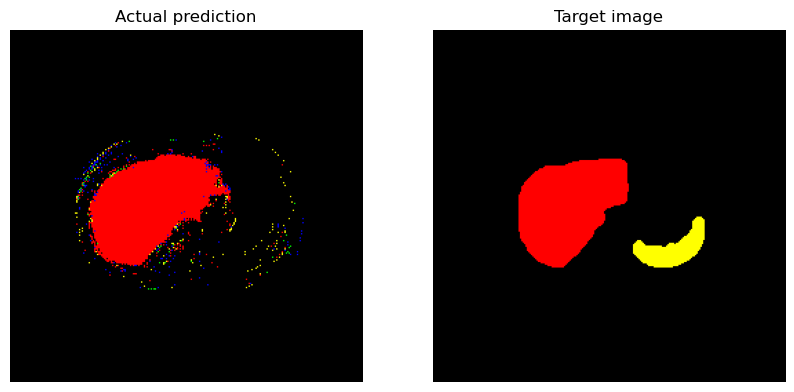

In [15]:
# Asume que tienes un DataLoader para tus datos de validación llamado dataloader_val
hist = pd.DataFrame()

log = {}
start_alpha = np.array([0.5,0.5,0.5,0.5,0.5])
alpha = start_alpha
fn = 0
flag_alpha = True

for epoch in range(num_epochs):
    model.train()  # Asegura que el modelo esté en modo de entrenamiento
    running_loss = 0.0
    for i, data in enumerate(dataloader_train, 0):
        inputs, labels = data
        inputs = inputs.to(device, dtype=torch.float)
        labels = labels.to(device, dtype=torch.long)

        optimizer.zero_grad()

        outputs = model(inputs)
        iou_metric.update((outputs, torch.argmax(labels, dim=1)))
        dice_metric.update((outputs,torch.argmax(labels, dim=1)))
        loss = criterion(outputs, torch.argmax(labels, dim=1))
        
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        

    #print(f'Train Epoch {epoch + 1}, Loss: {running_loss / len(dataloader_train)}', type(running_loss))
    
    log['loss'] = running_loss / len(dataloader_train)
    log['IoU'] = iou_no_bg_metric.compute().numpy()
    log['mIoU'] = mean_iou_no_bg_metric.compute().numpy()
    log['Dice'] = dice_metric.compute().numpy()
    log['alpha'] = alpha
    
    iou_metric.reset()
    dice_metric.reset()
    
    model.eval()  # Asegura que el modelo esté en modo de evaluación
    running_val_loss = 0.0
    with torch.no_grad():  # No necesitamos calcular gradientes para la validación
        for i, data in enumerate(dataloader_val, 0):
            inputs, labels = data
            inputs = inputs.to(device, dtype=torch.float)
            labels = labels.to(device, dtype=torch.long)

            outputs = model(inputs)
            iou_metric.update((outputs, torch.argmax(labels, dim=1)))
            dice_metric.update((outputs,torch.argmax(labels, dim=1)))
            val_loss = criterion(outputs, torch.argmax(labels, dim=1))
            
            running_val_loss += val_loss.item()

    #print(f'Val Epoch {epoch + 1}, Loss: {running_val_loss / len(dataloader_val)}', "IoU", iou_no_bg_metric.compute(), 'mean IoU', mean_iou_no_bg_metric.compute(), 'Dice', dice_metric.compute())
    
    log['val_loss'] = running_val_loss / len(dataloader_train)
    log['val_IoU'] = iou_no_bg_metric.compute().numpy()
    log['val_mIoU'] = mean_iou_no_bg_metric.compute().numpy()
    log['val_Dice'] = dice_metric.compute().numpy()
    
    iou_metric.reset()
    dice_metric.reset()
    
    hist = hist.append(log, ignore_index = True)
    hist.index.name = "epoch"
    
    df_view = hist.copy()
    for col in df_view.columns:
        df_view[col] = df_view[col].apply(lambda x: np.round(x,5))
    
    ####### Display images of training
    inputs, labels = x_temp
    inputs = inputs.to(device, dtype=torch.float)
    outputs = model(inputs)
    
    color_map = [
    (0, 0, 0),       # Clase 0: negro
    (255, 0, 0),     # Clase 1: azul
    (0, 255, 0),     # Clase 2: verde
    (0, 0, 255),     # Clase 3: rojo
    (255, 255, 0),   # Clase 4: amarillo
    # Agrega más colores si tienes más clases
    ]
    
    outputs = outputs.cpu()
    outputs = outputs.detach().numpy()
    outputs = np.argmax(outputs, axis=1)
    outputs = outputs[1]
    labels = labels.cpu()
    labels = labels.detach().numpy()
    labels = np.argmax(labels, axis=1)
    labels = labels[1]
    
    # Crea una imagen en color vacía con las mismas dimensiones que la máscara
    color_mask = np.zeros((outputs.shape[0], outputs.shape[1], 3), dtype=np.uint8)
    color_mask2 = np.zeros((outputs.shape[0], outputs.shape[1], 3), dtype=np.uint8)
    

    # Asigna el color correspondiente a cada clase en la imagen en color
    for label, color in enumerate(color_map):
       color_mask[outputs == label] = color
       color_mask2[labels == label] = color
    
    pyplot.clf()
    pyplot.subplot(1,2,1)
    pyplot.title("Actual prediction")
    pyplot.axis("off")
    pyplot.imshow(color_mask)
    pyplot.subplot(1,2,2)
    pyplot.title("Target image")
    pyplot.axis("off")
    pyplot.imshow(color_mask2)
    
    display.clear_output(wait=True)
    display.display(pyplot.gcf())
    display.display(df_view.tail(5))
    
    if epoch == 0:
        continue
    if epoch >= 4 and all((hist['alpha'].iloc[-5] == alphac).all() for alphac in hist['alpha'].iloc[-4:]):
        if flag_alpha:
            epoch_alpha = epoch
            flag_alpha = False
        display.display(print(f'alpha estable desde epoca {epoch_alpha}'))
        # display.display(hist.tail(5))
        continue
    delta_alpha = [act_alpha(class_sizes[i],hist['loss'].iloc[-2],hist['loss'].iloc[-1]) for i in range(len(class_sizes))]
    alpha = start_alpha - delta_alpha #alpha += delta_alpha ##sustituimos el alpha directamente
    criterion = FocalLoss(gamma=2, alpha=alpha.tolist())

display.display(print('Entrenamiento y validación finalizados'))

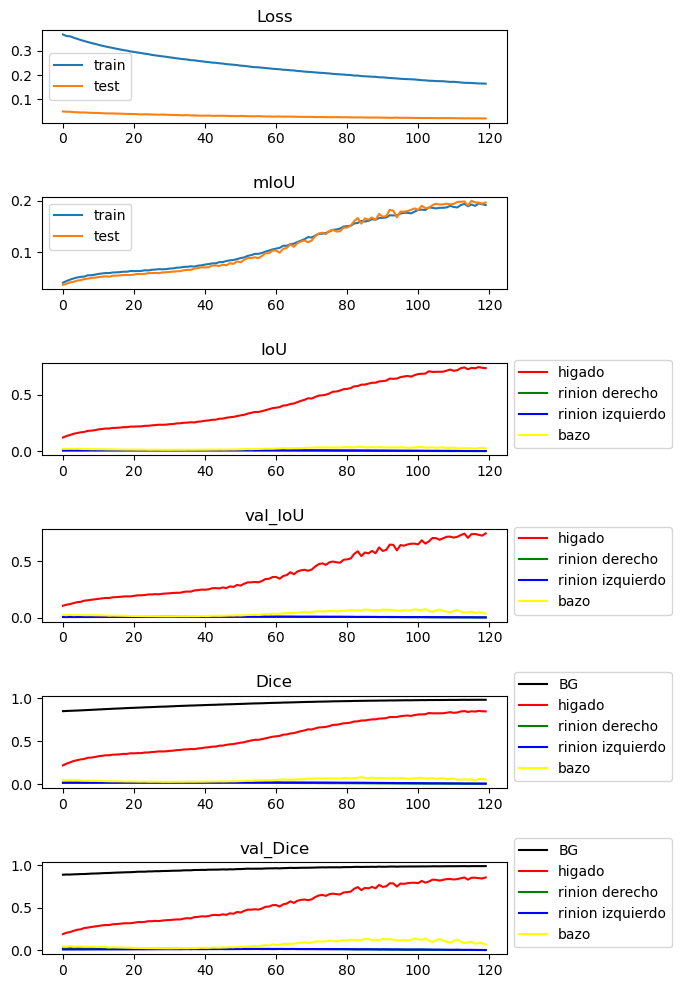

In [16]:
# Create a new figure and specify the size of the figure
pyplot.figure(figsize=(6, 12))    
# Some plots to check what is going on   
# loss function 
pyplot.subplot(611)
pyplot.title('Loss')
pyplot.plot(hist['loss'], label='train')
pyplot.plot(hist['val_loss'], label='test')
pyplot.legend()

# Only mean squared error 
pyplot.subplot(612)
pyplot.title('mIoU')
pyplot.plot(hist['mIoU'], label='train')
pyplot.plot(hist['val_mIoU'], label='test')
pyplot.legend()

pyplot.subplot(613)
pyplot.title('IoU')
pyplot.plot([x[0] for x in hist['IoU']], 'red', label='higado')
pyplot.plot([x[1] for x in hist['IoU']], 'green', label='rinion derecho')
pyplot.plot([x[2] for x in hist['IoU']], 'blue', label='rinion izquierdo')
pyplot.plot([x[3] for x in hist['IoU']], 'yellow', label='bazo')
pyplot.legend(loc='lower left',bbox_to_anchor=(1,0))

pyplot.subplot(614)
pyplot.title('val_IoU')
pyplot.plot([x[0] for x in hist['val_IoU']], 'red', label='higado')
pyplot.plot([x[1] for x in hist['val_IoU']], 'green', label='rinion derecho')
pyplot.plot([x[2] for x in hist['val_IoU']], 'blue', label='rinion izquierdo')
pyplot.plot([x[3] for x in hist['val_IoU']], 'yellow', label='bazo')
pyplot.legend(loc='lower left',bbox_to_anchor=(1,0))

pyplot.subplot(615)
pyplot.title('Dice')
pyplot.plot([x[0] for x in hist['Dice']], 'black', label='BG')
pyplot.plot([x[1] for x in hist['Dice']], 'red', label='higado')
pyplot.plot([x[2] for x in hist['Dice']], 'green', label='rinion derecho')
pyplot.plot([x[3] for x in hist['Dice']], 'blue', label='rinion izquierdo')
pyplot.plot([x[4] for x in hist['Dice']], 'yellow', label='bazo')
pyplot.legend(loc='lower left',bbox_to_anchor=(1,0))

pyplot.subplot(616)
pyplot.title('val_Dice')
pyplot.plot([x[0] for x in hist['val_Dice']], 'black', label='BG')
pyplot.plot([x[1] for x in hist['val_Dice']], 'red', label='higado')
pyplot.plot([x[2] for x in hist['val_Dice']], 'green', label='rinion derecho')
pyplot.plot([x[3] for x in hist['val_Dice']], 'blue', label='rinion izquierdo')
pyplot.plot([x[4] for x in hist['val_Dice']], 'yellow', label='bazo')
pyplot.legend(loc='lower left',bbox_to_anchor=(1,0))

# pyplot.subplot(515)
# pyplot.title('Alpha')
# pyplot.plot([alpha[0] for alpha in hist['alpha']], 'black', label='Background')
# pyplot.plot([alpha[1] for alpha in hist['alpha']], 'red', label='higado')
# pyplot.plot([alpha[2] for alpha in hist['alpha']], 'green', label='rinion derecho')
# pyplot.plot([alpha[3] for alpha in hist['alpha']], 'blue', label='rinion izquierdo')
# pyplot.plot([alpha[4] for alpha in hist['alpha']], 'yellow', label='bazo')
# pyplot.legend(loc='lower left',bbox_to_anchor=(1,0.2))

# This function adjusts the subplots automatically
pyplot.subplots_adjust(hspace = 0.8)
pyplot.show()

In [17]:
save_root = '/home/graciela/Adrian/Segmentacion_Unet_pytorch/Test_segmentation/'
save_path = save_root + f'unet_{num_epochs}ep_{type(criterion).__name__}'
counter = 0
while os.path.exists(save_path):
    counter += 1
    save_path = save_root + f'unet_{num_epochs}ep_{type(criterion).__name__}({counter})'

os.mkdir(save_path)
    
torch.save(model,save_path+"/model.pth")

os.mkdir(save_path + "/test_images")

In [18]:
import torch
model = torch.load('/home/graciela/Adrian/Segmentacion_Unet_pytorch/Test_segmentation/unet_10ep_CrossEntropyLoss/model.pth')
model.eval()

UNet(
  (encoder1): Encoder(
    (conv_block): ConvBlock(
      (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU()
    )
    (max_pool): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  )
  (encoder2): Encoder(
    (conv_block): ConvBlock(
      (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU()
    )
    (max_pool): MaxPool2d(kerne

In [19]:
model.eval()  # Asegura que el modelo esté en modo de evaluación
masks = []
with torch.no_grad():  # No necesitamos calcular gradientes para la validación
    for i, data in enumerate(dataloader_test, 0):
        inputs, labels = data
        inputs = inputs.to(device, dtype=torch.float)
        labels = labels.to(device, dtype=torch.long)

        outputs = model(inputs)
        masks.append(outputs.tolist())
        iou_metric.update((outputs, torch.argmax(labels, dim=1)))
        dice_metric.update((outputs,torch.argmax(labels, dim=1)))

print(f"test_IoU:{np.round(iou_no_bg_metric.compute().numpy(),5)}")
print(f"test_mIoU:{np.round(mean_iou_no_bg_metric.compute().numpy(),5)}")
print(f"test_Dice:{np.round(dice_metric.compute().numpy(),5)}")

iou_metric.reset()
dice_metric.reset()

test_IoU:[0.77974 0.61321 0.50585 0.67324]
test_mIoU:0.64301
test_Dice:[0.99377 0.87624 0.76024 0.67185 0.80471]


In [20]:
masks = np.array(masks)
masks = [np.array(masks[i,j,:,:]) for i in range(int(len(X_test)/batch_size)) for j in range(batch_size)]
len(masks)

112

In [21]:
y_test = np.argmax(y_test_one_hot, axis=1)
y_test.shape

torch.Size([112, 256, 256])

In [22]:
color_map = [
    (0, 0, 0),       # Clase 0: negro
    (0, 0, 255),     # Clase 1: azul
    (0, 255, 0),     # Clase 2: verde
    (255, 0, 0),     # Clase 3: rojo
    (0, 255, 255),   # Clase 4: amarillo
    # Agrega más colores si tienes más clases
]


for i, mask in enumerate(masks):
    mask = np.argmax(mask, axis=0)
    # Crea una imagen en color vacía con las mismas dimensiones que la máscara
    color_mask = np.zeros((mask.shape[0], mask.shape[1], 3), dtype=np.uint8)

    # Asigna el color correspondiente a cada clase en la imagen en color
    for label, color in enumerate(color_map):
        color_mask[mask == label] = color

    # Guarda la máscara de color como archivo .png
    output_path = save_path + "/test_images" + f'/segmented_image_{i}.png'
    cv2.imwrite(output_path, color_mask)
    print(f"image saved: {output_path}")

image saved: /home/graciela/Adrian/Segmentacion_Unet_pytorch/Test_segmentation/unet_120ep_FocalLoss(2)/test_images/segmented_image_0.png
image saved: /home/graciela/Adrian/Segmentacion_Unet_pytorch/Test_segmentation/unet_120ep_FocalLoss(2)/test_images/segmented_image_1.png
image saved: /home/graciela/Adrian/Segmentacion_Unet_pytorch/Test_segmentation/unet_120ep_FocalLoss(2)/test_images/segmented_image_2.png
image saved: /home/graciela/Adrian/Segmentacion_Unet_pytorch/Test_segmentation/unet_120ep_FocalLoss(2)/test_images/segmented_image_3.png
image saved: /home/graciela/Adrian/Segmentacion_Unet_pytorch/Test_segmentation/unet_120ep_FocalLoss(2)/test_images/segmented_image_4.png
image saved: /home/graciela/Adrian/Segmentacion_Unet_pytorch/Test_segmentation/unet_120ep_FocalLoss(2)/test_images/segmented_image_5.png
image saved: /home/graciela/Adrian/Segmentacion_Unet_pytorch/Test_segmentation/unet_120ep_FocalLoss(2)/test_images/segmented_image_6.png
image saved: /home/graciela/Adrian/Segmen

In [23]:
"""
color_map = [
    (0, 0, 0),       # Clase 0: negro
    (0, 0, 255),     # Clase 1: azul
    (0, 255, 0),     # Clase 2: verde
    (255, 0, 0),     # Clase 3: rojo
    (0, 255, 255),   # Clase 4: amarillo
    # Agrega más colores si tienes más clases
]


for i, mask in enumerate(y_test):
    # Crea una imagen en color vacía con las mismas dimensiones que la máscara
    color_mask = np.zeros((mask.shape[0], mask.shape[1], 3), dtype=np.uint8)

    # Asigna el color correspondiente a cada clase en la imagen en color
    for label, color in enumerate(color_map):
        color_mask[mask == label] = color

    # Guarda la máscara de color como archivo .png
    output_path = save_root + "/test_images" + f'/segmented_image_{i}.png'
    cv2.imwrite(output_path, color_mask)
    print(f"image saved: {output_path}")
"""

'\ncolor_map = [\n    (0, 0, 0),       # Clase 0: negro\n    (0, 0, 255),     # Clase 1: azul\n    (0, 255, 0),     # Clase 2: verde\n    (255, 0, 0),     # Clase 3: rojo\n    (0, 255, 255),   # Clase 4: amarillo\n    # Agrega más colores si tienes más clases\n]\n\n\nfor i, mask in enumerate(y_test):\n    # Crea una imagen en color vacía con las mismas dimensiones que la máscara\n    color_mask = np.zeros((mask.shape[0], mask.shape[1], 3), dtype=np.uint8)\n\n    # Asigna el color correspondiente a cada clase en la imagen en color\n    for label, color in enumerate(color_map):\n        color_mask[mask == label] = color\n\n    # Guarda la máscara de color como archivo .png\n    output_path = save_root + "/test_images" + f\'/segmented_image_{i}.png\'\n    cv2.imwrite(output_path, color_mask)\n    print(f"image saved: {output_path}")\n'